# 1- Support Vector Machine(SVC)
#### svc toy datasets

In [319]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification, make_moons, make_circles, load_breast_cancer, load_diabetes
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, SVR
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, mean_squared_error, r2_score

np.random.seed(42)
plt.rcParams['figure.figsize'] = (6, 4)


In [320]:
#create toy datasets
X_lin, y_lin= make_classification(
    n_samples=200,
    n_features=2,
    n_redundant=0,
    n_informative=2,
    n_clusters_per_class=1,
    class_sep=1.8,
    random_state=42,
)

y_lin[:10]

array([1, 1, 1, 1, 1, 0, 1, 0, 0, 0])

Text(0.5, 1.0, 'Visualize toy datasets')

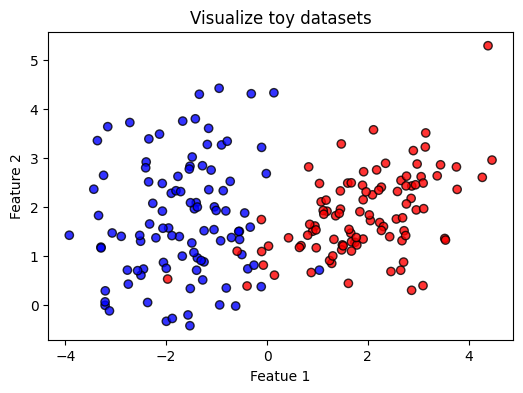

In [321]:
# visualize toy datasets

plt.figure()
plt.scatter(X_lin[:,0],X_lin[:,1],edgecolors='k', c=y_lin, alpha=0.8, cmap='bwr')
plt.xlabel('Featue 1')
plt.ylabel('Feature 2')
plt.title('Visualize toy datasets')

In [322]:
#train test split
X_train, X_test, y_train, y_test= train_test_split(X_lin, y_lin, test_size=0.2, random_state=42)

#standar scaler
scaler= StandardScaler()
X_train_scaler= scaler.fit_transform(X_train)
X_test_scaler= scaler.transform(X_test)


In [323]:
#modal train SVM
svm_linear= SVC(kernel='linear', C=1.0, random_state=42)
svm_linear.fit(X_train_scaler, y_train)

SVC(kernel='linear', random_state=42)

In [324]:
#model predict
y_pred=svm_linear.predict(X_test_scaler)
print('accuracy:',accuracy_score(y_test, y_pred))

accuracy: 0.975


In [325]:
# Helper function to plot decision boundary for 2D data
def plot_decision_boundary(model,x,y,title='Decision bonundaey'):
  x_min, x_max=x[:,0].min()-1, x[:,0].max()+1
  y_min,y_max=x[:,1].min()-1, x[:,1].max()+1
  #full graph a mesggrid apply (300x300)
  xx, yy=np.meshgrid(
      np.linspace(x_min,x_max, 300),
      np.linspace(y_min,y_max,300)
  )

  #1d
  grid=np.c_[xx.ravel(),yy.ravel()]
  #predict
  Z=model.predict(grid)
  #return 2d
  Z = Z.reshape(xx.shape)

  #plot dec boundaey
  plt.contourf(xx, yy,Z,c=y, cmap='bwr', alpha=0.2)
  plt.scatter(x[:,0], x[:,1],c=y, cmap='bwr',edgecolors='k', alpha=0.8)
  plt.title(title)
  plt.xlabel('Feature 1')
  plt.ylabel('Feature 2')
  plt.show()

/tmp/ipykernel_3237/2866817422.py:19: UserWarning: The following kwargs were not used by contour: 'c'
  plt.contourf(xx, yy,Z,c=y, cmap='bwr', alpha=0.2)


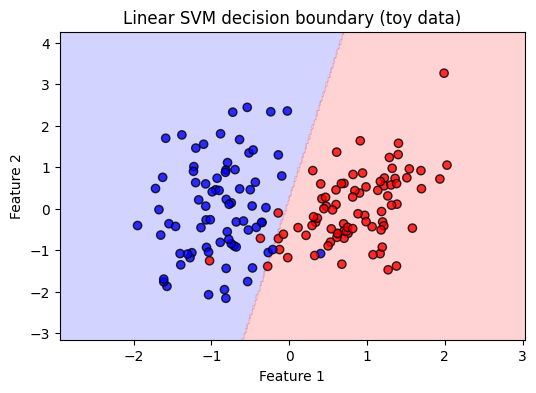

In [326]:
#call helper function
plot_decision_boundary(svm_linear, X_train_scaler,y_train, title='Linear SVM decision boundary (toy data)')

#Kernels: Linear, Polynomial, and RBF

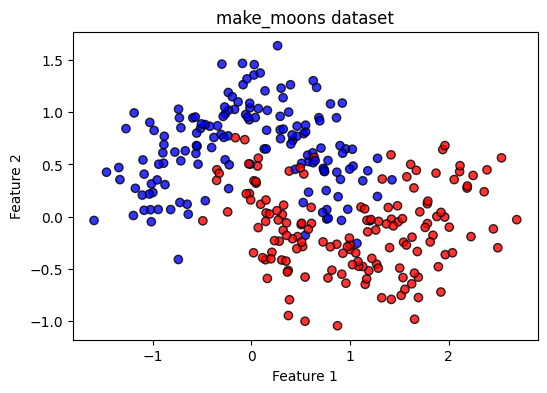

In [327]:
#generate moon datasets(nonlinear)
X_moon,y_moon= make_moons(n_samples=300,noise=0.25, random_state=42)

#datasets visualization
plt.scatter(X_moon[:,0], X_moon[:,1], alpha=0.8, c=y_moon,cmap='bwr', edgecolors='k' )
plt.title('make_moons dataset')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

In [328]:
#train  test split
X_moon_train, X_moon_test, y_moon_train, y_moon_test= train_test_split(X_moon, y_moon, test_size=0.2, random_state=42)

#scaler
scaler_moon= StandardScaler()
X_train_scaled=scaler_moon.fit_transform(X_moon_train)
X_test_scaled=scaler_moon.transform(X_moon_test)

###Model  svc Linear


/tmp/ipykernel_3237/2866817422.py:19: UserWarning: The following kwargs were not used by contour: 'c'
  plt.contourf(xx, yy,Z,c=y, cmap='bwr', alpha=0.2)


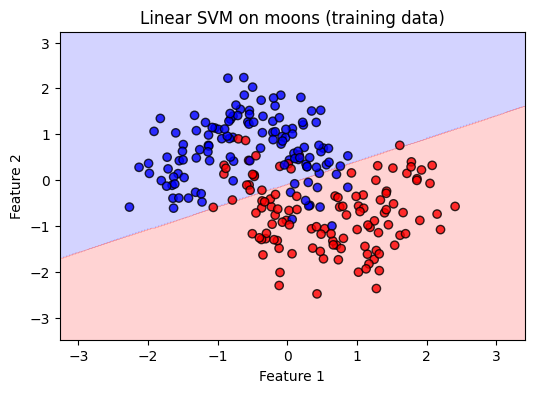

Accuracy (linear kernel on moons): 0.8833333333333333


In [329]:
# Linear kernel on moons
svc_linear_moon = SVC(kernel='linear', C=1.0, random_state=42)
svc_linear_moon.fit(X_train_scaled, y_moon_train)
plot_decision_boundary(svc_linear_moon, X_train_scaled, y_moon_train,
                       title='Linear SVM on moons (training data)')
print('Accuracy (linear kernel on moons):', accuracy_score(y_moon_test,
      svc_linear_moon.predict(X_test_scaled)))

##Model use POly

/tmp/ipykernel_3237/2866817422.py:19: UserWarning: The following kwargs were not used by contour: 'c'
  plt.contourf(xx, yy,Z,c=y, cmap='bwr', alpha=0.2)


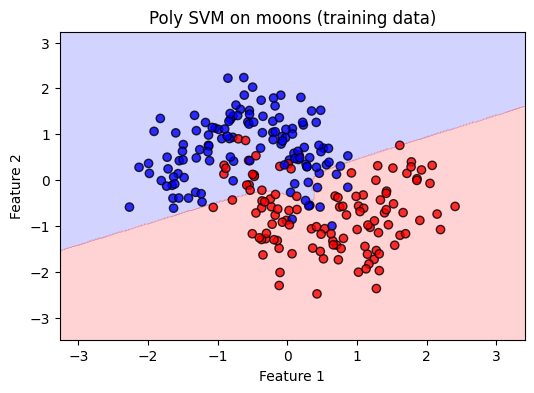

Accuracy (linear kernel on moons): 0.9


In [330]:
# Linear kernel on moons
svc_poly_moon = SVC(kernel='poly',degree=3,gamma='scale', C=20.0, random_state=42)
svc_poly_moon.fit(X_train_scaled, y_moon_train)
plot_decision_boundary(svc_poly_moon, X_train_scaled, y_moon_train,
                       title='Poly SVM on moons (training data)')
print('Accuracy (linear kernel on moons):', accuracy_score(y_moon_test,
      svc_poly_moon.predict(X_test_scaled)))

##Model use RBF

/tmp/ipykernel_3237/2866817422.py:19: UserWarning: The following kwargs were not used by contour: 'c'
  plt.contourf(xx, yy,Z,c=y, cmap='bwr', alpha=0.2)


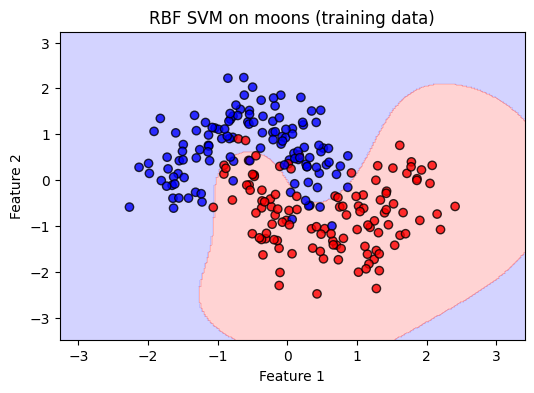

Accuracy (linear kernel on moons): 0.9333333333333333


In [331]:
# Linear kernel on moons
svc_rbf_moon = SVC(kernel='rbf',gamma='scale', C=10.0, random_state=42)
svc_rbf_moon.fit(X_train_scaled, y_moon_train)
plot_decision_boundary(svc_rbf_moon, X_train_scaled, y_moon_train,
                       title='RBF SVM on moons (training data)')
print('Accuracy (linear kernel on moons):', accuracy_score(y_moon_test,
      svc_rbf_moon.predict(X_test_scaled)))

# SVM Classification on Real Data (Breast Cancer Dataset)

In [332]:
#load breast cancer dataset
cancer = load_breast_cancer()
X_bc= cancer.data
y_bc=cancer.target
print('Feature shape:', X_bc.shape)
print('Classes:', cancer.target_names)

Feature shape: (569, 30)
Classes: ['malignant' 'benign']


In [333]:
#train test split and scaling
X_bc_train, X_bc_test, y_bc_train, y_bc_test= train_test_split(X_bc, y_bc, test_size=0.2, random_state=42, stratify=y_bc)

#standerscaler
scaler_bc = StandardScaler()
X_bc_train_scaled = scaler_bc.fit_transform(X_bc_train)
X_bc_test_scaled = scaler_bc.transform(X_bc_test)

# Train an RBF SVM classifier on breast cancer data
svc_bc=SVC(kernel='rbf',C=1.0, gamma='scale',random_state=42)
svc_bc.fit(X_bc_train_scaled, y_bc_train)

y_bc_pred = svc_bc.predict(X_bc_test_scaled)
acc_bc = accuracy_score(y_bc_test, y_bc_pred)
print("Accuracy with RBF: ", acc_bc)

print('\nClassification report:')
print(classification_report(y_bc_test, y_bc_pred, target_names=cancer.target_names))

Accuracy with RBF:  0.9824561403508771

Classification report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [334]:
# Confusion matrix
cm = confusion_matrix(y_bc_test, y_bc_pred)
print('Confusion matrix:\n', cm)

Confusion matrix:
 [[41  1]
 [ 1 71]]


In [335]:
def evaluate_svm_c_gamma(X_train, X_test, y_train, y_test, C_values, gamma_values):
    results = []
    for C in C_values:
        for gamma in gamma_values:
            model = SVC(kernel='rbf', C=C, gamma=gamma, random_state=42)
            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)
            acc = accuracy_score(y_test, y_pred)
            results.append({'C': C, 'gamma': gamma, 'accuracy': acc})
    return pd.DataFrame(results)

C_values = [0.1, 1.0, 10.0]
gamma_values = ['scale', 0.01, 0.1, 1.0]

df_hyper = evaluate_svm_c_gamma(X_bc_train_scaled, X_bc_test_scaled,
                                y_bc_train, y_bc_test,
                                C_values, gamma_values)
df_hyper

,C,gamma,accuracy
0,0.1,scale,0.947368
1,0.1,0.01,0.956140
2,0.1,0.1,0.947368
3,0.1,1.0,0.631579
4,1.0,scale,0.982456
5,1.0,0.01,0.982456
6,1.0,0.1,0.956140
7,1.0,1.0,0.631579
8,10.0,scale,0.973684
9,10.0,0.01,0.982456


In [336]:
# Sort by accuracy to see top combinations
df_hyper.sort_values('accuracy', ascending=False)

,C,gamma,accuracy
5,1.0,0.01,0.982456
9,10.0,0.01,0.982456
4,1.0,scale,0.982456
8,10.0,scale,0.973684
6,1.0,0.1,0.956140
1,0.1,0.01,0.956140
0,0.1,scale,0.947368
2,0.1,0.1,0.947368
10,10.0,0.1,0.947368
3,0.1,1.0,0.631579


# 2 - Introduction to Support Vector Regression (SVR)

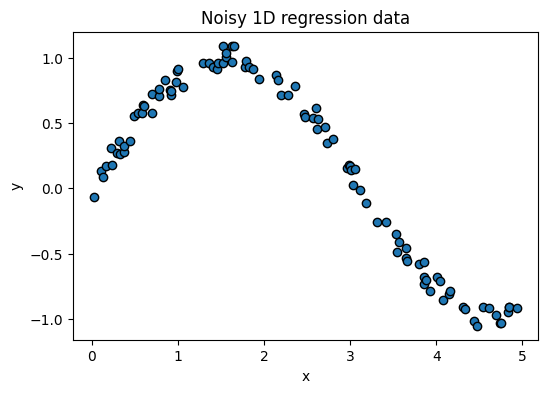

In [337]:
# Create a simple 1D regression dataset
rng = np.random.RandomState(42)
X_reg = np.sort(5 * rng.rand(100, 1), axis=0)
y_reg = np.sin(X_reg).ravel()

# Add noise
y_reg += 0.2 * (rng.rand(y_reg.shape[0]) - 0.5)

plt.scatter(X_reg, y_reg, edgecolors='k')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Noisy 1D regression data')
plt.show()

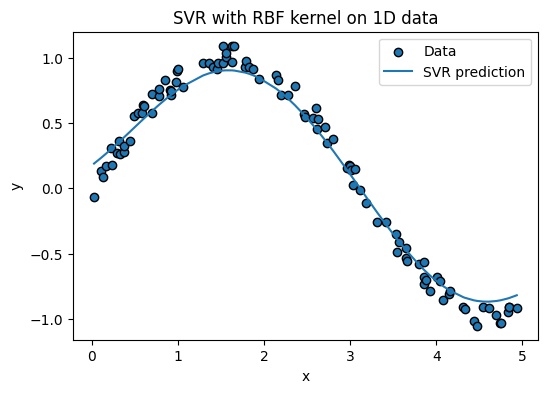

In [338]:
#train svr  eith brf kernel
svr_brf= SVR(kernel='rbf', gamma='scale',C=0.1, epsilon=0.1)
svr_brf.fit(X_reg,y_reg)

y_reg_pred=svr_brf.predict(X_reg)

plt.scatter(X_reg, y_reg, edgecolors='k', label='Data')
plt.plot(X_reg,y_reg_pred,label='SVR prediction')
plt.xlabel('x')
plt.ylabel('y')
plt.title('SVR with RBF kernel on 1D data')
plt.legend()
plt.show()

In [339]:
# Evaluate SVR with MSE and R^2
mse = mean_squared_error(y_reg, y_reg_pred)
r2 = r2_score(y_reg, y_reg_pred)

print("MSE: ", mse)
print("R^2: ",r2)

MSE:  0.008659453875945123
R^2:  0.9818609249737438


##SVR on Real Data (Diabetes Dataset)

In [340]:
# Load diabetes dataset
diabetes = load_diabetes()
X_diab = diabetes.data
y_diab = diabetes.target

print('Feature-shape:', X_diab.shape)

# Train test split
X_diab_train, X_diab_test, y_diab_train, y_diab_test = train_test_split(
    X_diab, y_diab, test_size=0.2, random_state=42
)

scaler_diab = StandardScaler()
X_diab_train_scaled = scaler_diab.fit_transform(X_diab_train)
X_diab_test_scaled = scaler_diab.transform(X_diab_test)

Feature-shape: (442, 10)


In [341]:
# Train SVR diabetes data
svr_diab= SVR(kernel='rbf', C=10.0, epsilon=0.1, gamma='scale')
svr_diab.fit(X_diab_train_scaled, y_diab_train)

y_diab_pred= svr_diab.predict(X_diab_test_scaled)

mse_diab= mean_squared_error(y_diab_test, y_diab_pred)
r2_diab= r2_score(y_diab_test, y_diab_pred)

print("MSE: ", mse_diab)
print("R^2: ", r2_diab)

MSE:  2682.387949725229
R^2:  0.4937125101265256
